<a href="https://colab.research.google.com/github/odoalawaye/Pytorch-Tutorial/blob/main/PINNs_Coffee.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**PINNs Cooling rate of coffee**

In [73]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

**Physics parameters**

In [74]:
# Physics parameters
T_env = 25.0  # Room temperature (°C)
T0 = 90.0     # Initial coffee temperature (°C)
k = 0.1       # Cooling rate constant

#True analytical solution

In [75]:
# True analytical solution
def true_solution(t):
    return T_env + (T0 - T_env)*np.exp(-k*t)

In [76]:
# Generate some time points (every 2 minutes for 20 minutes)
t_min, t_max = 0.0, 20.0
t_data = np.array([0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 20])

In [77]:
# Generate noisy temperature measurements
np.random.seed(0)
noise_level = 2.0  # ±2°C measurement error
T_data_exact = true_solution(t_data)
T_data_noisy = T_data_exact + noise_level*np.random.randn(len(t_data))

In [78]:
T_data_exact

array([90.        , 78.21749895, 68.57080299, 60.67275635, 54.20638267,
       48.91216368, 44.57762377, 41.02880266, 38.12327367, 35.74442773,
       33.79679341])

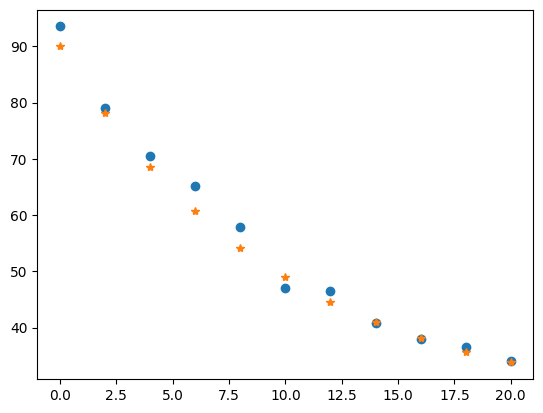

In [79]:
plt.plot(t_data,T_data_noisy,'o')
plt.plot(t_data,T_data_exact,'*')
plt.show()

In [80]:
# Convert to PyTorch tensors
t_data_tensor = torch.tensor(t_data, dtype=torch.float32).view(-1, 1)
T_data_tensor = torch.tensor(T_data_noisy, dtype=torch.float32).view(-1, 1)

#Define the Neural Network
A simple neural network that takes time t and predicts temperature T.

In [81]:
class CoffeePINN(nn.Module):
    def __init__(self):
        super(CoffeePINN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 20),  # 1 input (time), 20 hidden neurons
            nn.Tanh(),
            nn.Linear(20, 20),
            nn.Tanh(),
            nn.Linear(20, 1)   # 1 output (temperature)
        )

    def forward(self, t):
        return self.net(t)

model = CoffeePINN()

#Define the Physics Loss
This ensures the network follows Newton’s Law of Cooling.

In [82]:
def derivative(y, x):
    """Computes dy/dx using autograd"""
    return torch.autograd.grad(y, x,
                             grad_outputs=torch.ones_like(y),
                             create_graph=True)[0]

def physics_loss(model, t):
    """Physics loss: dT/dt = -k*(T - T_env)"""
    t.requires_grad_(True)

    # Get prediction and derivative
    T = model(t)
    dT_dt = derivative(T, t)

    # Governing equation residual
    residual = dT_dt + k*(T - T_env)
    return torch.mean(residual**2)

#Define Data & Initial Condition Losses
Data Loss: Fits noisy measurements.

IC Loss: Ensures initial temperature is correct.

In [83]:
def data_loss(model, t_data, T_data):
    """MSE between predictions and measurements"""
    T_pred = model(t_data)
    return torch.mean((T_pred - T_data)**2)

def initial_condition_loss(model):
    """Initial condition: T(0) = T0"""
    t0 = torch.zeros(1, 1, dtype=torch.float32)
    T_pred = model(t0)
    return (T_pred - T0).pow(2).mean()


#Train the PINN
We optimize all three losses together.

In [84]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

# Loss weights (you can adjust these)
lambda_data = 1.0
lambda_ode = 1.0
lambda_ic = 1.0

num_epochs = 2000
print_every = 200

model.train()
for epoch in range(num_epochs):
    optimizer.zero_grad()

    # Compute all loss components
    l_data = data_loss(model, t_data_tensor, T_data_tensor)
    l_ode = physics_loss(model, t_data_tensor)
    l_ic = initial_condition_loss(model)

    # Combined loss
    loss = lambda_data*l_data + lambda_ode*l_ode + lambda_ic*l_ic

    # Backpropagation
    loss.backward()
    optimizer.step()

    # Print progress
    if (epoch + 1) % print_every == 0:
        print(f"Epoch {epoch+1}/{num_epochs}, "
              f"Total Loss = {loss.item():.4f}, "
              f"Data Loss = {l_data.item():.4f}, "
              f"ODE Loss = {l_ode.item():.4f}, "
              f"IC Loss = {l_ic.item():.4f}")

Epoch 200/2000, Total Loss = 3144.3882, Data Loss = 597.2145, ODE Loss = 2.1218, IC Loss = 2545.0520
Epoch 400/2000, Total Loss = 973.2415, Data Loss = 138.0450, ODE Loss = 4.5904, IC Loss = 830.6060
Epoch 600/2000, Total Loss = 209.3176, Data Loss = 27.4610, ODE Loss = 4.2610, IC Loss = 177.5956
Epoch 800/2000, Total Loss = 38.6028, Data Loss = 7.8778, ODE Loss = 3.4762, IC Loss = 27.2488
Epoch 1000/2000, Total Loss = 9.5948, Data Loss = 3.0934, ODE Loss = 3.8964, IC Loss = 2.6050
Epoch 1200/2000, Total Loss = 5.8110, Data Loss = 1.8100, ODE Loss = 3.9256, IC Loss = 0.0753
Epoch 1400/2000, Total Loss = 1.8787, Data Loss = 1.6359, ODE Loss = 0.2218, IC Loss = 0.0210
Epoch 1600/2000, Total Loss = 1.4823, Data Loss = 1.2821, ODE Loss = 0.1276, IC Loss = 0.0725
Epoch 1800/2000, Total Loss = 1.4019, Data Loss = 1.1816, ODE Loss = 0.1336, IC Loss = 0.0868
Epoch 2000/2000, Total Loss = 1.3631, Data Loss = 1.1356, ODE Loss = 0.1427, IC Loss = 0.0849


#Visualize the Results

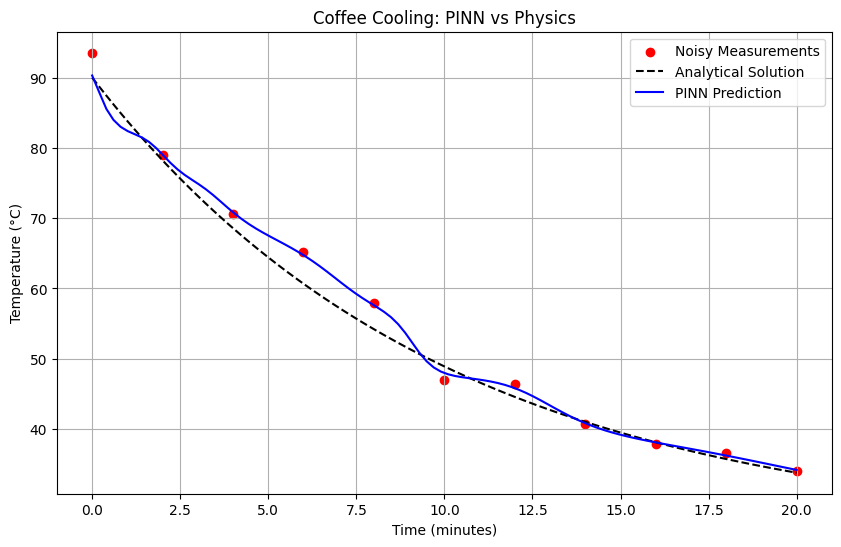

In [85]:
model.eval()
t_plot = np.linspace(t_min, t_max, 100).reshape(-1, 1)
t_plot_tensor = torch.tensor(t_plot, dtype=torch.float32)
T_pred_plot = model(t_plot_tensor).detach().numpy()

# True solution for comparison
T_true_plot = true_solution(t_plot)

# Plot results
plt.figure(figsize=(10, 6))
plt.scatter(t_data, T_data_noisy, color='red', label='Noisy Measurements')
plt.plot(t_plot, T_true_plot, 'k--', label='Analytical Solution')
plt.plot(t_plot, T_pred_plot, 'b', label='PINN Prediction')
plt.xlabel('Time (minutes)')
plt.ylabel('Temperature (°C)')
plt.title('Coffee Cooling: PINN vs Physics')
plt.legend()
plt.grid(True)
plt.show()